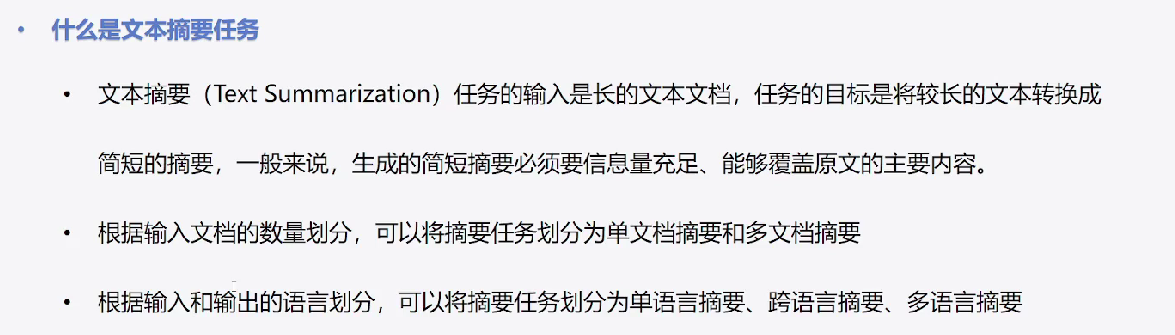

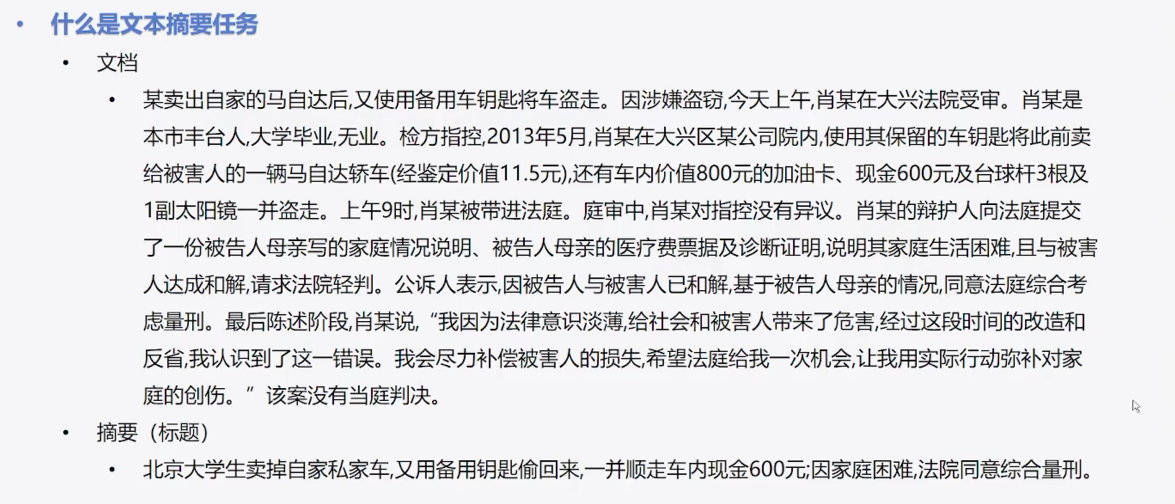

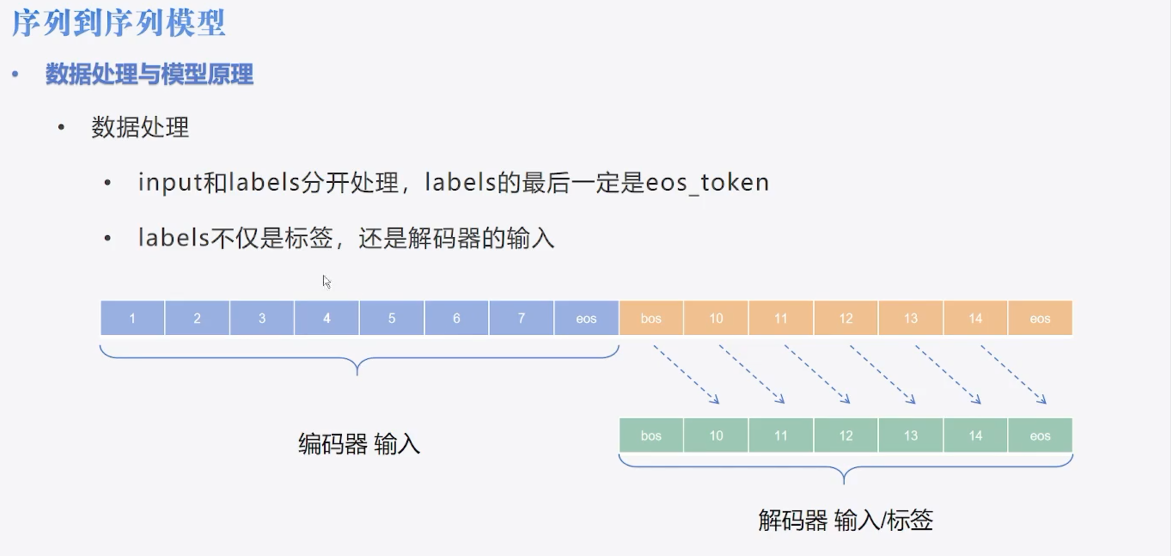

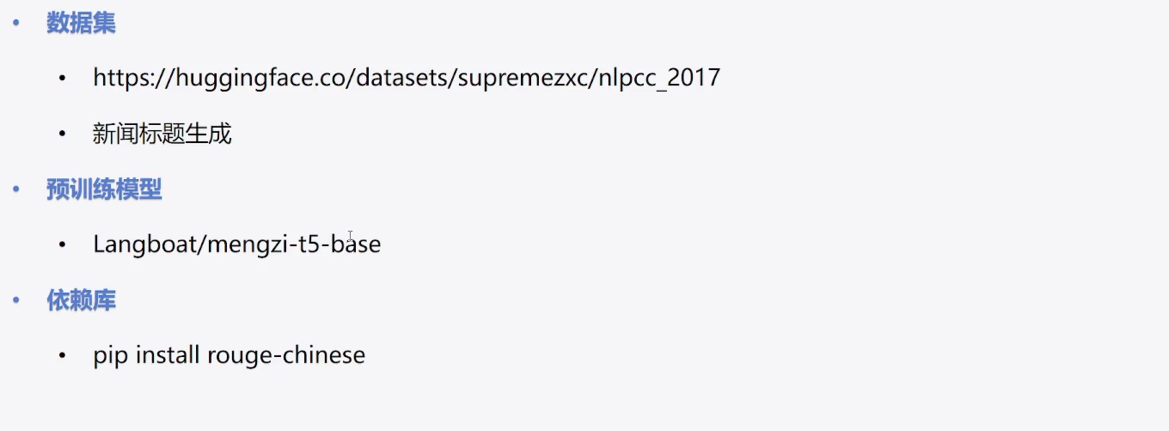

In [ ]:
import os
os.environ['HF_ENDPOINT'] = 'https://hf-mirror.com'

import torch
from datasets import load_dataset, load_from_disk
from transformers import( AutoTokenizer, AutoModelForSeq2SeqLM,
                         T5TokenizerFast,
                         Seq2SeqTrainingArguments,
                         Seq2SeqTrainer,
                         DataCollatorForSeq2Seq)#使用rust语言的tokenizer速度很快
import numpy as np
import evaluate
# from rouge_chinese import Rouge


dataset = load_dataset("supremezxc/nlpcc_2017",split="train",cache_dir="/teacher_train/wtb/data/nlpcc_2017")

# dataset = load_from_disk("/teacher_train/wtb/data/nlpcc_2017/supremezxc___nlpcc_2017/")
dataset = dataset.train_test_split(test_size=0.2)

print(dataset['train'].column_names)


#pip install sentencepiece 安装sentencepiece 不安装就只能用 T5TokenizerFast 安装就可以用 AutoTokenizer

# model_name = "Langboat/mengzi-t5-base"
tokenizer = T5TokenizerFast.from_pretrained("/teacher_train/model/mengzi-t5-base/",local_files_only=True)
tokenizer.save_pretrained("/teacher_train/model/mengzi-t5-base/")  # 生成 tokenizer.json T5TokenizerFast要是必须有
model = AutoModelForSeq2SeqLM.from_pretrained("/teacher_train/model/mengzi-t5-base/",local_files_only=True)

def preprocess_fun(examples):
    # examples['data'] 是一个列表，需要遍历它来获取 content
    contents=["摘要生成:\n"+e['content'] for e in examples["data"]]
    inputs = tokenizer(contents,max_length=350,truncation=True)
    
    # 修改处：同样遍历 examples['data'] 来提取 title
    labels = tokenizer(text_target=[e['title'] for e in examples['data']], max_length=64, truncation=True)
    
    inputs['labels'] = labels['input_ids']
    return inputs

dataset = dataset.map(preprocess_fun, batched=True,remove_columns=dataset["train"].column_names)


# rouge = Rouge()
# def compute_metric(evalPred):
#     pre,labels = evalPred
#     #解码
#     decode_pre =tokenizer.batch_decode(pre,skip_special_tokens=True)
    
#     labels = np.where(labels !=-100,labels,tokenizer.pad_token_id)
    
#     decode_labels = tokenizer.batch_decode(labels,skip_special_tokens=True)
    
#     decode_pre = [" ".join(p) for p in decode_pre]
#     decode_labels = [" ".join(l) for l in decode_labels]
#     scores = rouge.get_scores(decode_pre,decode_labels,avg=True)
    
#     return {
#         "rouge-1":scores['rouge-1']['f'],
#         "rouge-2":scores['rouge-2']['f'],
#         "rouge-l":scores['rouge-l']['f']
#     }


#需要装
#pip install absl-py rouge-score nltk
rouge = evaluate.load("rouge")
def compute_metric(evalPred):
    """
    1. Trainer 遍历验证集 DataLoader
   ├─ 批次1: 模型推理 → 暂存预测和标签
   ├─ 批次2: 模型推理 → 暂存预测和标签
   ├─ 批次3: 模型推理 → 暂存预测和标签 
   └─ ... 直到遍历完所有批次

2. 收集所有批次的预测和标签

3. 调用 compute_metrics(eval_pred)
   └─ eval_pred 包含整个验证集的所有预测和标签
    """
    
    pre, labels = evalPred
    # 解码
    decode_pre = tokenizer.batch_decode(pre, skip_special_tokens=True)
    #skip_special_tokens=True 会去掉像 <pad>, <s>, </s> 这样的特殊符号，只保留有意义的文本。
    
    labels = np.where(labels != -100, labels, tokenizer.pad_token_id)
    # 逻辑：如果 labels 中的元素 != -100，就保持原值；否则（即等于 -100），替换为 pad_token_id
    #在 Hugging Face 的训练逻辑对于标签序列（labels）的填充，它默认会将其设为 -100。
    #计算 Loss 时，我们不需要计算 padding 位置的 Loss。
    #如果标签也是 pad_token_id（比如 0），模型预测错 padding 也会产生 Loss，这是不合理的。
    #通过把标签设为 -100，PyTorch 的 Loss 函数会自动忽略这些位置，只计算有效文本的 Loss。
    """
    用一个小例子你就能直观看到
    pad_token_id = 0
    labels = [71, 18, -100, -100]
    替换后：
    labels = [71, 18, 0, 0]
    这样 batch_decode 才能正常工作；解码时 <pad> 通常会被跳过。
    关键点总结
    训练 loss：需要 -100 来“忽略 padding”
    评估/解码：需要把 -100 变成 pad_token_id，否则解码/指标计算不方便甚至报错
    """
    
    decode_labels = tokenizer.batch_decode(labels, skip_special_tokens=True)

    # 分词处理：在字符间加空格以适配 ROUGE 靠空格分词来判断词
    decode_pre = [" ".join(p) for p in decode_pre]
    decode_labels = [" ".join(l) for l in decode_labels]
    #你才是真的狗 转换成  你 才 是 真 的 狗
    
    # 3. 使用 evaluate 的 compute 方法
    scores = rouge.compute(predictions=decode_pre, references=decode_labels,tokenizer=lambda x: x.split())
    
    # 4. 返回结果 (evaluate 的 rouge 直接返回字典，包含 rouge1, rouge2, rougeL, rougeLsum)
    return {
        "rouge1": scores['rouge1'],
        "rouge2": scores['rouge2'],
        "rougeL": scores['rougeL']
    }


args = Seq2SeqTrainingArguments(
    output_dir="/teacher_train/wtb/finetun/T5/",
    per_device_train_batch_size=4,
    per_device_eval_batch_size=8,
    gradient_accumulation_steps=16,
    logging_steps=8,
    predict_with_generate=True,  #运行生成的概率值转换为对应的序列，否则只有概率值 测试函数需要的是id不是概率
    num_train_epochs=10,
    save_total_limit=3,
    save_steps=100,
    save_strategy="steps",
    eval_steps=100,
    eval_strategy="steps",
    metric_for_best_model="rougeL",
    load_best_model_at_end=True,
)

trainer = Seq2SeqTrainer(
    args=args,
    model=model,
    train_dataset=dataset["train"],
    eval_dataset=dataset["test"],
    compute_metrics=compute_metric,
    tokenizer=tokenizer,
    data_collator=DataCollatorForSeq2Seq(tokenizer=tokenizer)
)

trainer.train()

trainer.save_model()